# RQ1: Prediction Accuracy
**Research Question 1:** *How accurately does the IFS-based Recommender System predict missing stakeholder ratings?*

To answer this, we evaluate the prediction quality across **all three RALIC datasets** (Objectives, Requirements, and Specific Requirements) using 10-fold cross-validation. The known ratings are randomly divided into 10 equal folds. In each run, 1 fold is removed (used as the test set) and predicted from the remaining 9 folds (training set).

We evaluate the Mean Absolute Error (MAE) against different fuzzification functions, hesitation degrees ($\pi$), nearest neighbors ($k$), and two distinct recommendation strategies:
* **Global:** Predicts based on overall stakeholder similarities.
* **Local:** Predicts based only on neighbors who have actively rated the target requirement.

In [1]:
# Import core libraries for data manipulation, cross-validation, and performance evaluation
import time
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error

# Import custom framework modules for fuzzification, similarity computation, and prediction
from src.data_loader import load_ralic
from src.fuzzification import convert_to_ifv_matrix, defuzzify_to_numeric
from src.similarity import get_similarity_matrices
from src.recommender import predict_missing_values

# Configure global settings for output clarity and visualization styling
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

### 1. K-Fold Cross-Validation & Multi-Dataset Grid Search
We loop through RALIC datasets 1, 2, and 3. For each dataset, we extract all valid coordinates, run the 10-Fold CV, and test every combination of our framework parameters.

*(Note: Depending on the hardware, processing 3 datasets × 2 strategies × 3 fuzzification methods × 8 hesitation values × 75 neighbor limits × 10 folds = 108,000 matrix calculations may take a very long time to complete. The full grind results are already saved in the /results folder. To test and verify Specific Combination Parameters, change the appropriate parameters and run the following code.)*

In [2]:
# Full Grid Search Parameters - Uncomment as required to run the full grid search
# datasets = [1, 2, 3]  # 1: Objectives, 2: Requirements, 3: Specific Reqs
# strategies = ['global', 'local']
# fuzzification_methods = ['linear', 'r-trapezoidal', 'sigmoidal']
# hesitation_degrees = np.arange(0.0, 0.45, 0.05)
# k_neighbors_list = np.arange(1, 76)

# Specific Combination Parameters to run specific combinations - Comment as required to run the full grid search
datasets = [2]  # 1: Objectives, 2: Requirements, 3: Specific Reqs
strategies = ['global'] # 'global', 'local'
fuzzification_methods = ['linear'] # 'linear', 'r-trapezoidal', 'sigmoidal'
hesitation_degrees = [0.3] # 0.0 to 0.4 in steps of 0.05
k_neighbors_list = [29] # 1 to 75

results = []
total_start_time = time.time()

print("Starting K-Fold Cross-Validation Grid Search...")
print("=" * 80)

for data_id in datasets:
    print(f"\n>>> Loading RALIC Dataset {data_id}...")
    df_ralic, _, _, _ = load_ralic(data_id=data_id, base_path='../data/')
    valid_coords = np.argwhere(~df_ralic.isna().values)
    # Initialize k-fold split to validate predictive performance
    kf = KFold(n_splits=10, shuffle=True, random_state=100)
    
    for strategy in strategies:
        for method in fuzzification_methods:
            for pi in hesitation_degrees:
                for k_nn in k_neighbors_list:
                    fold_maes = []

                    for train_idx, test_idx in kf.split(valid_coords):
                        test_coords = valid_coords[test_idx]
                        
                        # Mask the test coordinates to simulate unrated requirements
                        df_train = df_ralic.copy()
                        for r, c in test_coords:
                            df_train.iat[r, c] = np.nan
                        
                        # Transform continuous numeric ratings into Intuitionistic Fuzzy Values (IFVs)
                        df_train_ifv = convert_to_ifv_matrix(
                            df_train, method=method, pi=pi, 
                            scale_min=-1.0, scale_max=5.0, trap_limit_min=0.0, trap_limit_max=4.0
                        )
                        
                        # Calculate pairwise stakeholder similarities using the H-max distance measure
                        _, sim_matrix = get_similarity_matrices(df_train_ifv)
                        
                        # Execute collaborative filtering to predict missing evaluations
                        df_pred_ifv = predict_missing_values(df_train_ifv, sim_matrix, k=k_nn, strategy=strategy)
                        
                        # Extract and defuzzify predicted values for error calculation
                        y_true = []
                        y_pred = []
                        
                        for r, c in test_coords:
                            true_val = df_ralic.iat[r, c]
                            pred_ifv = df_pred_ifv.iat[r, c]
                            
                            if isinstance(pred_ifv, tuple) and not np.isnan(pred_ifv[0]):
                                pred_val = defuzzify_to_numeric(pred_ifv, min_scale=-1.0, max_scale=5.0)
                            else:
                                # Apply default penalty constraint for completely disconnected nodes
                                pred_val = -1.0
                            
                            y_true.append(true_val)
                            y_pred.append(pred_val)
                        
                        if y_true:
                            fold_maes.append(mean_absolute_error(y_true, y_pred))
                    
                    # Aggregate Mean Absolute Error across all evaluation folds
                    avg_mae = np.mean(fold_maes)
                    results.append({
                        'Dataset': f'RALIC {data_id}', 
                        'Strategy': strategy,
                        'Fuzzification': method, 
                        'Uncertainty (pi)': pi, 
                        'Neighbors (k)': k_nn, 
                        'MAE': avg_mae
                    })
                    
                    print(f"Strategy: {strategy:<6} | Method: {method:<10} | pi: {pi:.2f} | k: {k_nn:<2} --> MAE: {avg_mae:.4f}")

print("=" * 80)
print(f"Grid Search Complete in {time.time() - total_start_time:.2f} seconds.")
df_results = pd.DataFrame(results)
display(df_results)

Starting K-Fold Cross-Validation Grid Search...

>>> Loading RALIC Dataset 2...
Strategy: global | Method: linear     | pi: 0.30 | k: 29 --> MAE: 0.8694
Grid Search Complete in 10.15 seconds.


,Dataset,Strategy,Fuzzification,Uncertainty (pi),Neighbors (k),MAE
0,RALIC 2,global,linear,0.3,29,0.869446


### 2. Exporting Results & Visualization
We save the output of the grid search into three distinct CSV files for downstream reporting, and we visualize the prediction accuracy using a multi-panel Seaborn grid.

*(Note: The full grid results are already saved as csv files in the /results folder and loaded for further analysis.)*

In [3]:
# Export the Full Grid Search Results
# df_results.to_csv('../results/rq1_results.csv', index=False)

import pandas as pd
import matplotlib.pyplot as plt
results_path = '../results/rq1_results.csv'

print(f"Loading full experimental results from '{results_path}'...\n")
df_results = pd.read_csv(results_path)

# Extract the best MAE for each Dataset, Strategy and Fuzzification
best_per_pi = df_results.loc[df_results.groupby(['Dataset', 'Strategy', 'Fuzzification'])['MAE'].idxmin()]
print("--- Best MAE for each Dataset, Strategy and Fuzzification ---")
display(best_per_pi[['Dataset', 'Strategy', 'Fuzzification', 'Uncertainty (pi)', 'Neighbors (k)', 'MAE']].style.format({'MAE': '{:.3f}'}).hide(axis="index"))

# Extract Best Overall MAE per Dataset and Strategy
best_overall = df_results.loc[df_results.groupby(['Dataset', 'Strategy'])['MAE'].idxmin()]
print("--- Absolute Best MAE per Dataset and Strategy ---")
display(best_overall[['Dataset', 'Strategy', 'Fuzzification', 'Uncertainty (pi)', 'Neighbors (k)', 'MAE']].style.format({'MAE': '{:.3f}'}).hide(axis="index"))

Loading full experimental results from '../results/rq1_results.csv'...

--- Best MAE for each Dataset, Strategy and Fuzzification ---


Dataset,Strategy,Fuzzification,Uncertainty (pi),Neighbors (k),MAE
RALIC 1,global,linear,0.400000,44,0.789
RALIC 1,global,r-trapezoidal,0.400000,45,0.779
RALIC 1,global,sigmoidal,0.000000,44,0.792
RALIC 1,local,linear,0.250000,14,0.780
RALIC 1,local,r-trapezoidal,0.400000,14,0.757
RALIC 1,local,sigmoidal,0.000000,12,0.790
RALIC 2,global,linear,0.300000,29,0.869
RALIC 2,global,r-trapezoidal,0.400000,25,0.876
RALIC 2,global,sigmoidal,0.000000,40,0.996
RALIC 2,local,linear,0.150000,2,0.739


--- Absolute Best MAE per Dataset and Strategy ---


Dataset,Strategy,Fuzzification,Uncertainty (pi),Neighbors (k),MAE
RALIC 1,global,r-trapezoidal,0.400000,45,0.779
RALIC 1,local,r-trapezoidal,0.400000,14,0.757
RALIC 2,global,linear,0.300000,29,0.869
RALIC 2,local,linear,0.150000,2,0.739
RALIC 3,global,r-trapezoidal,0.400000,16,0.768
RALIC 3,local,linear,0.050000,2,0.607


### 3. Baseline Comparison (Proposed Framework vs. StakeRare)
To validate the performance of our proposed IFS-based Recommender System, we compare the absolute best configurations (Global and Local strategies) discovered during the grid search against the established **StakeRare** baseline for all three RALIC datasets.

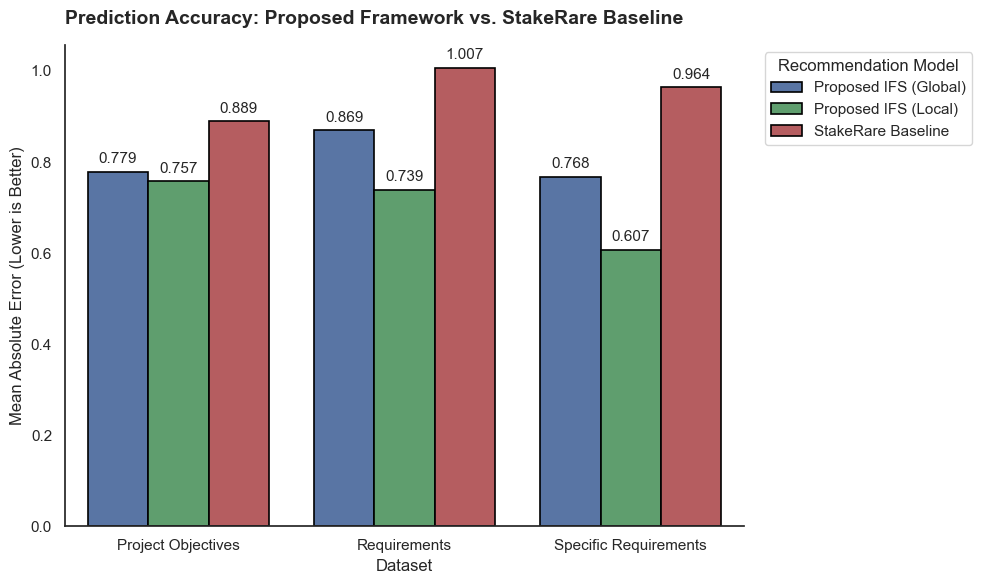

In [4]:
# Define prediction error baselines from established literature
stakerare_baselines = {
    'RALIC 1': 0.889, # Project Objectives
    'RALIC 2': 1.007, # Requirements
    'RALIC 3': 0.964  # Specific Requirements
}

dataset_titles = {
    'RALIC 1': 'Project Objectives',
    'RALIC 2': 'Requirements',
    'RALIC 3': 'Specific Requirements'
}

# Restructure data for a grouped bar chart
plot_data = []

# Extract proposed framework data
for index, row in best_overall.iterrows():
    dataset_name = dataset_titles.get(row['Dataset'], row['Dataset'])
    model_name = 'Proposed IFS (Global)' if row['Strategy'] == 'global' else 'Proposed IFS (Local)'
    plot_data.append({
        'Dataset': dataset_name,
        'Recommendation Model': model_name,
        'MAE': row['MAE']
    })

# Extract baseline data
for ds_key, baseline in stakerare_baselines.items():
    dataset_name = dataset_titles.get(ds_key, ds_key)
    plot_data.append({
        'Dataset': dataset_name,
        'Recommendation Model': 'StakeRare Baseline',
        'MAE': baseline
    })

plot_df = pd.DataFrame(plot_data)

# Set visualization style (white background, no grids)
sns.set_theme(style="white")
plt.figure(figsize=(10, 6))

# Define custom colors to match the requested aesthetic
custom_palette = {
    'Proposed IFS (Global)': '#4C72B0',
    'Proposed IFS (Local)': '#55A868',
    'StakeRare Baseline': '#C44E52'
}

# Generate grouped bar plot (errorbar=None removes vertical lines on bars)
ax = sns.barplot(
    data=plot_df,
    x='Dataset',
    y='MAE',
    hue='Recommendation Model',
    palette=custom_palette,
    edgecolor='black',
    linewidth=1.2,
    errorbar=None
)

# Annotate bars with precise MAE values
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.3f}',
                    xy=(p.get_x() + p.get_width() / 2, height),
                    xytext=(0, 4),  # 4 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=11)

# Set title and axes labels
plt.title('Prediction Accuracy: Proposed Framework vs. StakeRare Baseline',
          fontsize=14, weight='bold', loc='left', pad=15)
plt.ylabel('Mean Absolute Error (Lower is Better)', fontsize=12)
plt.xlabel('Dataset', fontsize=12)

# Move legend outside the plot
plt.legend(title='Recommendation Model', bbox_to_anchor=(1.02, 1), loc='upper left')

# Remove top and right borders for a cleaner look
sns.despine()

plt.tight_layout()
plt.savefig('../results/rq1_baseline_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

### 4. Statistical Analysis (ANOVA & Tukey HSD)
To evaluate the statistical significance of the proposed approach, we apply an Analysis of Variance (ANOVA) to the MAE metric. By applying this model, we simultaneously evaluate how the choice of $k$-nn, fuzzification function, hesitation degree, and recommendation strategy affects the prediction accuracy.

Following the ANOVA, we perform a Multiple Pairwise Comparison (Tukey HSD) to explicitly identify which fuzzification functions yield statistically different performance.

In [5]:
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import warnings
import pandas as pd
# Suppress statsmodels warnings for cleaner output
warnings.filterwarnings('ignore', module='statsmodels')

# Load the complete experimental dataset for variance analysis
results_path = '../results/rq1_results.csv'
df_results = pd.read_csv(results_path)
df_anova = df_results.copy()

# Sanitize structural column names to comply with statsmodels formula conventions
df_anova = df_anova.rename(columns={
    'Neighbors (k)': 'knn',
    'Uncertainty (pi)': 'hesitation',
    'Fuzzification': 'fuzzification',
    'Strategy': 'strategy'
})

# Execute independent statistical models for each evaluation dataset
for dataset in df_anova['Dataset'].unique():
    print(f"\n{'='*80}")
    print(f"STATISTICAL ANALYSIS: {dataset}")
    print(f"{'='*80}")

    df_ds = df_anova[df_anova['Dataset'] == dataset]

    # Define the N-Way ANOVA formula
    # Model: MAE influenced by knn, fuzzification, hesitation, strategy, and their key interactions
    formula = (
        'MAE ~ C(knn) + C(fuzzification) + C(hesitation) + C(strategy) + '
        'C(knn):C(hesitation) + C(knn):C(fuzzification) + C(knn):C(strategy) + '
        'C(fuzzification):C(hesitation) + C(fuzzification):C(strategy) + '
        'C(hesitation):C(strategy)'
    )

    print("Fitting ANOVA model...")
    model = ols(formula, data=df_ds).fit()
    anova_results = sm.stats.anova_lm(model, typ=2)

    # Calculate Mean Square variances
    anova_results['Mean Square'] = anova_results['sum_sq'] / anova_results['df']

    anova_formatted = pd.DataFrame({
        'Source': anova_results.index,
        'Sum of Squares': anova_results['sum_sq'],
        'df': anova_results['df'],
        'Mean Square': anova_results['Mean Square'],
        'F': anova_results['F'],
        'Sig.': anova_results['PR(>F)']
    }).reset_index(drop=True)

    # Standardize residual labeling
    anova_formatted['Source'] = anova_formatted['Source'].replace('Residual', 'Error')

    print(f"\nTable: Results of ANOVA for MAE - {dataset}")
    display(anova_formatted.style.format({
        'Sum of Squares': '{:.3f}',
        'df': '{:.0f}',
        'Mean Square': '{:.3f}',
        'F': '{:.2f}',
        'Sig.': '{:.3f}'
    }).hide(axis="index"))

    # TUKEY HSD (Pairwise Comparisons for Fuzzification)
    # Performs post-hoc analysis to find exactly which functions outperformed the others
    tukey = pairwise_tukeyhsd(endog=df_ds['MAE'], groups=df_ds['fuzzification'], alpha=0.01)
    tukey_df = pd.DataFrame(data=tukey._results_table.data[1:], columns=tukey._results_table.data[0])

    # Construct tabular representation of pairwise mean differences and confidence intervals
    tukey_formatted = pd.DataFrame({
        'Group 1': tukey_df['group1'],
        'Group 2': tukey_df['group2'],
        'Mean Difference': tukey_df['meandiff'],
        'Lower Bound': tukey_df['lower'],
        'Upper Bound': tukey_df['upper'],
        'p-value': tukey_df['p-adj']
    })

    # Format high-significance thresholds dynamically
    tukey_formatted['p-value'] = tukey_formatted['p-value'].apply(lambda x: '<.001' if x < 0.001 else f"{x:.3f}")

    print(f"\nTable: Multiple pairwise comparisons for fuzzification - {dataset}")
    display(tukey_formatted.style.format({
        'Mean Difference': '{:.3f}',
        'Lower Bound': '{:.3f}',
        'Upper Bound': '{:.3f}'
    }).hide(axis="index"))


STATISTICAL ANALYSIS: RALIC 1
Fitting ANOVA model...

Table: Results of ANOVA for MAE - RALIC 1


Source,Sum of Squares,df,Mean Square,F,Sig.
C(knn),56.133,74,0.759,5667.08,0.000
C(fuzzification),6.335,2,3.168,23664.65,0.000
C(hesitation),2.985,8,0.373,2787.29,0.000
C(strategy),4.874,1,4.874,36414.86,0.000
C(knn):C(hesitation),0.121,592,0.000,1.53,0.000
C(knn):C(fuzzification),0.129,148,0.001,6.52,0.000
C(knn):C(strategy),38.613,74,0.522,3898.37,0.000
C(fuzzification):C(hesitation),6.398,16,0.400,2987.47,0.000
C(fuzzification):C(strategy),0.006,2,0.003,22.06,0.000
C(hesitation):C(strategy),0.006,8,0.001,5.81,0.000



Table: Multiple pairwise comparisons for fuzzification - RALIC 1


Group 1,Group 2,Mean Difference,Lower Bound,Upper Bound,p-value
linear,r-trapezoidal,-0.032,-0.050,-0.013,<.001
linear,sigmoidal,0.063,0.045,0.082,<.001
r-trapezoidal,sigmoidal,0.095,0.077,0.114,<.001



STATISTICAL ANALYSIS: RALIC 2
Fitting ANOVA model...

Table: Results of ANOVA for MAE - RALIC 2


Source,Sum of Squares,df,Mean Square,F,Sig.
C(knn),26.492,74,0.358,1531.14,0.000
C(fuzzification),7.139,2,3.570,15266.78,0.000
C(hesitation),0.134,8,0.017,71.87,0.000
C(strategy),3.563,1,3.563,15238.21,0.000
C(knn):C(hesitation),0.341,592,0.001,2.47,0.000
C(knn):C(fuzzification),1.973,148,0.013,57.02,0.000
C(knn):C(strategy),30.981,74,0.419,1790.64,0.000
C(fuzzification):C(hesitation),1.988,16,0.124,531.54,0.000
C(fuzzification):C(strategy),0.048,2,0.024,101.99,0.000
C(hesitation):C(strategy),0.025,8,0.003,13.21,0.000


... (2 outputs left out)


STATISTICAL ANALYSIS: RALIC 3
Fitting ANOVA model...

Table: Results of ANOVA for MAE - RALIC 3


Source,Sum of Squares,df,Mean Square,F,Sig.
C(knn),27.595,74,0.373,958.61,0.000
C(fuzzification),11.220,2,5.610,14421.64,0.000
C(hesitation),0.112,8,0.014,35.92,0.000
C(strategy),0.935,1,0.935,2403.87,0.000
C(knn):C(hesitation),0.338,592,0.001,1.47,0.000
C(knn):C(fuzzification),2.912,148,0.020,50.57,0.000
C(knn):C(strategy),19.407,74,0.262,674.16,0.000
C(fuzzification):C(hesitation),2.964,16,0.185,476.13,0.000
C(fuzzification):C(strategy),0.041,2,0.020,52.61,0.000
C(hesitation):C(strategy),0.017,8,0.002,5.59,0.000



Table: Multiple pairwise comparisons for fuzzification - RALIC 3


Group 1,Group 2,Mean Difference,Lower Bound,Upper Bound,p-value
linear,r-trapezoidal,0.045,0.032,0.058,<.001
linear,sigmoidal,0.127,0.114,0.140,<.001
r-trapezoidal,sigmoidal,0.082,0.069,0.095,<.001
